# WildSpeech V3 — Speech-Model Installation, Child ASR, Phonetic Intelligence & Reading Prediction (P23–P29)

**Question.** Do children's actual pronunciations, phoneme errors, speech confidence and acoustic representations predict
end-of-year reading outcomes *beyond* the screening scores (tabular GAM, R² ≈ 0.215)?

**Models (registry `configs/v3_asr_models.yaml`, schema 3, pinned commits + sha256 manifests):**
pasketti_phonetic (WavLM-CTC, IPA) · whisper_small_en · pasketti_word (Qwen3-ASR, qwen_asr+vLLM, WSL2 only) ·
wav2vec2_phoneme_espeak · wav2vec2_base_960h · frozen encoders wav2vec2_base · hubert_base · wavlm_base_plus.

**Eligibility = 13 independent dimensions → one lifecycle status** (LEGAL_REVIEW_PENDING, PROVENANCE_REVIEW_PENDING,
READY_FOR_DOWNLOAD, DOWNLOADING, CHECKPOINT_INCOMPLETE, FRAMEWORK_INCOMPATIBLE, READY_FOR_INFERENCE, INFERENCE_RUNNING,
INFERENCE_COMPLETE, INELIGIBLE, FAILED). Approvals exist only as named human reviews in `configs/v3_asr_reviews.yaml`;
`configs/v3_asr_review_proposals.yaml` holds drafts that approve nothing. A completed eligibility check is never inference.

**Switches (cell 0):** `RUN_PIPELINE` (stages), `ALLOW_MODEL_DOWNLOADS` (installs approved models only),
`RUN_SMOKE` (few-clip GPU decode). All default to `False`: the notebook then only reads local files.

| § | Section | § | Section |
|---|---|---|---|
| 1 | Environment & GPU diagnostics | 9 | ASR disagreement (P27) |
| 2 | Model eligibility | 10 | Embedding extraction |
| 3 | Download & checkpoint status | 11 | Reading regression / compact representations (P28) |
| 4 | Model-loading diagnostics & smoke test | 12 | Cross-validation & ablations (P29) |
| 5 | ASR inference (P24) | 13 | Scientific plots |
| 6 | Transcript & phoneme inspection | 14 | Champion comparison |
| 7 | Phonetic feature extraction (P25) | 15 | Final report |
| 8 | Correct-response analysis (P26) | | |

## 0. Configuration

In [1]:
# ===== central control =====
RUN_PIPELINE = False            # True = actually execute stages (GPU inference + repeated CV)
ALLOW_MODEL_DOWNLOADS = False   # True = install models whose reviews ALL pass (pinned commit, sha256-verified)
RUN_SMOKE = False               # True = few-clip GPU decode per READY_FOR_INFERENCE model (cache/v3/asr_smoke)
PROFILE = "V3_FULL"             # V3_SMOKE | V3_AUDIT | V3_ASR | V3_SCIENCE | V3_FULL | V3_SUBMISSION
FORCE = []                      # e.g. ["P24"] to recompute a stage
DEEP_CHECK = True               # instantiate processors / tokenizers of installed snapshots (no weights)
VERIFY_HASHES = False           # sha256 every installed weight file now (cached afterwards)
OVERRIDES = {
    # "v3": {"asr": {"max_clips": 500}},                                  # quick pass
    # "v3": {"asr": {"models": ["pasketti_phonetic", "whisper_small_en", "wav2vec2_base_960h"]}},
    # "v3": {"runtime": {"max_repeats": 1}},                              # first CV repeat only
}
if ALLOW_MODEL_DOWNLOADS:
    OVERRIDES.setdefault("v3", {}).setdefault("asr", {}).setdefault("downloads", {})["allow_model_downloads"] = True

import sys
from pathlib import Path

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(REPO / "src") not in sys.path:
    sys.path.insert(0, str(REPO / "src"))

import pandas as pd
from IPython.display import display, Markdown
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 120)

from wildspeech.v3 import notebook as nb

ctx = nb.context(PROFILE, OVERRIDES)
print("profile:", ctx.profile, "| device:", ctx.device, "| data:", ctx.paths.data_dir)
print("outputs:", ctx.paths.v3_root, "| caches:", ctx.paths.v3_cache)

12:54:18 | INFO    | context: profile=V3_FULL device=cuda root=C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU data=C:\Users\myben\Downloads\WildSpeech_P01\data


profile: V3_FULL | device: cuda | data: C:\Users\myben\Downloads\WildSpeech_P01\data
outputs: C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\outputs\V3 | caches: C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\cache\v3


In [2]:
# Reference numbers are READ from saved artefacts (never hard-coded)
b = ctx.bundle()
print(f"train students={len(b.train)}  train clips={len(b.train_clips)}  test students={len(b.test_students)}")
p10 = ctx.read_stage_table("P10", "model_benchmark")
if p10 is not None:
    ok = p10[p10["status"] == "ok"].sort_values("r2_mean", ascending=False)
    display(ok.head(5)[["name", "model", "families", "r2_mean", "r2_sd"]])
p17 = ctx.read_stage_table("P17", "clip_metrics")
if p17 is not None and "auroc" in p17:
    display(p17.sort_values("auroc", ascending=False).head(5))
p21 = ctx.read_stage_table("P21", "all_results")
if p21 is not None:
    z = p21[(p21["delta_r2"].abs() < 1e-12) & (p21["group"] != "comparator")]
    print(f"V2 P21: {len(z)} of {len(p21)} rows report ΔR² exactly 0 -> audited in P23")
# status incl. the truth about P24 (a pre-fix 'completed' P24 without inference is flagged)
display(nb.status(ctx))

12:54:18 | INFO    | data: train 541 students / 14704 clips, test 361 / 9814, tasks=['blending', 'deletion', 'sentence_repetition'], thetas=['blending_theta', 'deletion_theta', 'sentence_repetition_theta']


train students=541  train clips=14704  test students=361


,name,model,families,r2_mean,r2_sd
17,B_GAM__SCREENING+BEHAVIOR+ITEM,GAM,SCREENING+BEHAVIOR+ITEM,0.215256,0.002120
2,B_RIDGE__SCREENING+BEHAVIOR+ITEM,RIDGE,SCREENING+BEHAVIOR+ITEM,0.212404,0.008279
7,B_ELASTIC_NET__SCREENING+BEHAVIOR+ITEM,ELASTIC_NET,SCREENING+BEHAVIOR+ITEM,0.211863,0.007338
16,B_GAM__SCREENING+RECORDING,GAM,SCREENING+RECORDING,0.200903,0.006763
15,B_GAM__SCREENING,GAM,SCREENING,0.199539,0.007460


,feature_set,model,n,prevalence,auroc,auprc,auprc_incorrect,bacc,brier,logloss,ece
23,HARMONIZED,MLP,14635,0.487257,0.860297,0.858090,0.862524,0.771508,0.152485,0.463743,0.017864
11,TEMPORAL,MLP,14635,0.487257,0.856107,0.854174,0.857430,0.771947,0.154313,0.468790,0.013626
27,COMBINED,MLP,14635,0.487257,0.856063,0.854994,0.857890,0.771823,0.154658,0.469285,0.017166
20,HARMONIZED,LOGISTIC,14635,0.487257,0.853396,0.850854,0.854756,0.768094,0.156198,0.474226,0.017908
24,COMBINED,LOGISTIC,14635,0.487257,0.852402,0.850255,0.854186,0.767392,0.156944,0.475990,0.021015


V2 P21: 62 of 95 rows report ΔR² exactly 0 -> audited in P23


,stage,name,status,up_to_date,seconds,finished,note,enabled,expensive,asr_truth
21,P21,multimodal_v2,completed,True,1896.292852,2026-11-20T19:02:06,,True,False,
23,P23,fusion_audit,completed,True,1318.791161,2026-11-20T23:28:29,,True,False,
24,P24,asr,not_executed,None,12.396887,2026-11-21T12:53:10,eligibility only: no speech model is READY_FOR_INFERENCE (see model_eligibility.csv / required_actions.csv); no infe...,True,True,ELIGIBILITY_ONLY (inference_executed=False)
25,P25,phonetic_features,not_executed,None,0.251743,2026-11-21T12:53:10,needs >= 1 model(s) with real ASR text outputs on ['train']; accepted: none; rejected caches: pasketti_phonetic/trai...,True,False,
26,P26,correct_only,blocked,None,0.000000,2026-11-21T01:00:59,waiting for ['P25'],True,False,
27,P27,asr_disagreement,blocked,None,0.000000,2026-11-21T01:01:02,waiting for ['P25'],True,False,
28,P28,representations,never_run,None,NaN,None,,True,False,
29,P29,reading_ablation,never_run,None,NaN,None,,True,False,


In [3]:
# Execution plan (dry run — never executes anything)
display(nb.plan(ctx, ["P23", "P24", "P25", "P26", "P27", "P28", "P29"]))

,stage,status,note
0,P23,cached,2026-11-20T23:28:29
1,P24,would_run,"eligible local child/general ASR inference (resumable, provenance-tracked)"
2,P25,would_run,expected-text-conditioned word/phoneme/confidence/timing/task features
3,P26,would_run,"correct-response speech intelligence (item-conditioned, fold-fitted)"
4,P27,would_run,ASR model disagreement and consensus
5,P28,would_run,"compact phonetic representations (nested, budget-controlled)"
6,P29,would_run,"reading prediction ASR00-ASR12, robustness, controls, champion comparison"


### 0.1 P23 — Fusion audit (exact-zero ΔR², silent fallbacks, stale lineage)
Re-runs the V2 specs with per-fold tracing; reproduces the GAM baseline; repairs the V1 task ensemble.

In [4]:
display(nb.run_stages(ctx, ["P23"], FORCE, enabled=RUN_PIPELINE))

RUN_PIPELINE is False -> showing the plan only (nothing executed)


,stage,status,note
0,P23,cached,2026-11-20T23:28:29


--- baseline_reproduction


,name,experiment,group,scheme,status,model,fusion,method,providers,budget,control,r2_mean,r2_sd,r2_pooled,r2_fold_mean,r2_repeat_avg_pred,rmse,mae,fold_r2_min,n_added,n_features,fallback_folds,n_folds,identical_to_baseline,max_abs_diff_vs_baseline,reason,v2_r2_mean,reproduced
0,V2_BASELINE,ASR00,baseline,repeated_kfold,ok,GAM,early,none,NaN,NaN,NaN,0.215256,0.00212,0.215256,0.21601,0.218545,9.855957,7.298695,0.077397,0.0,108.0,15,15,NaN,NaN,NaN,0.215256,True


--- fusion_verdicts


,audited,scheme,status,verdict,delta_r2_reported,delta_r2_reproduced,reproduced,fallback_folds,n_folds,delta_r2_forced_alpha,delta_r2_v3_reducer,max_abs_diff_vs_baseline
0,P21_ALL_RESIDUAL_RIDGE,repeated_kfold,fallback_baseline,silent_fallback,0.000000,0.000000,True,15,15,-0.008432,0.000000,0.000000
1,P21_BUDGET_ALL_100,repeated_kfold,fallback_baseline,silent_fallback,0.000000,0.000000,True,15,15,-0.010843,0.000000,0.000000
2,P21_FUSION_EARLY,repeated_kfold,ok,genuine_negative,-0.028075,-0.028075,True,0,15,NaN,-0.033250,7.215799
3,P21_FUSION_LATE,repeated_kfold,partial_fallback,genuine_negative,-0.001912,-0.001912,True,1,15,NaN,-0.006091,10.167011
4,P21_FUSION_TASK_POOL,repeated_kfold,ok,genuine_negative,-0.000320,-0.000320,True,0,15,NaN,0.001733,7.270351
5,P21_SINGLE_CPX,repeated_kfold,fallback_baseline,silent_fallback,0.000000,0.000000,True,15,15,-0.000314,0.000000,0.000000
6,P21_SINGLE_HARM,repeated_kfold,fallback_baseline,silent_fallback,0.000000,0.000000,True,15,15,-0.008949,0.000000,0.000000
7,P21_SINGLE_REF,repeated_kfold,fallback_baseline,silent_fallback,0.000000,0.000000,True,15,15,-0.001497,0.000000,0.000000
8,P21_SINGLE_SOFT,repeated_kfold,fallback_baseline,silent_fallback,0.000000,0.000000,True,15,15,-0.001424,0.000000,0.000000


--- v2_budget_cap


,family,budgets,n_added_values,max_n_added,capped
0,ALL,"5,10,20,50,100","5.0,10.0,20.0,36.0",36.0,True
1,CPX,"5,10,20,50,100","5.0,6.0",6.0,True
2,HARM,"5,10,20,50,100","5.0,10.0",10.0,True
3,REF,"5,10,20,50,100","5.0,10.0",10.0,True
4,SOFT,"5,10,20,50,100","5.0,10.0",10.0,True


... (3 outputs left out)

,stage,status,profile,finished,recorded_fp,current_fp,stale_under_current_config,upstream_changed_since_run,n_upstream_changed,hard_deps,soft_deps,note
0,P16,completed,V2_FULL,2026-11-20T17:31:21,0589839a6e987e33,0589839a6e987e33,False,NaN,0.0,P01,"P02,P10",NaN
1,P18,completed,V2_FULL,2026-11-20T18:02:47,2121d8adde3bd95e,2121d8adde3bd95e,False,NaN,0.0,P01,NaN,NaN
2,P20,completed,V2_FULL,2026-11-20T18:25:58,b02ebbcaac915254,b02ebbcaac915254,False,NaN,0.0,P01,NaN,NaN
3,P17,completed,V2_FULL,2026-11-20T18:29:55,4252eea2e8c27362,4252eea2e8c27362,False,NaN,0.0,P16,"P18,P20,P10",NaN
4,P19,completed,V2_FULL,2026-11-20T18:30:31,e9dbc73d2e2bb020,e9dbc73d2e2bb020,False,NaN,0.0,P16,"P18,P20",NaN
5,P21,completed,V2_FULL,2026-11-20T19:02:06,b33d681d79d06225,b33d681d79d06225,False,NaN,0.0,P17,"P16,P18,P19,P20,P10",NaN
6,P22,never_run,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,P10,completed,FULL,2026-11-20T15:29:06,69df870789d6258c,69df870789d6258c,False,NaN,0.0,P05,P09,NaN
8,P11,completed,FULL,2026-11-20T15:33:59,20059fd948422493,20059fd948422493,False,NaN,0.0,P10,NaN,NaN


--- v3_repairs


,issue,v3_fix
0,residual fusion alpha=0 reported as ΔR²=0 'ok',status fallback_baseline; never reported as a result; forced/continuous-alpha diagnostics
1,budget capped by family_components=10,CompactReducer: components follow the budget
2,budget selection on IN-SAMPLE ridge residual,selection target = inner-OOF residual of the training fold
3,V1 task ensemble unbounded NNLS weights / extreme members,"RobustTaskEnsemble (convex weights, winsorised inputs, missing-task gating, clipping) + extreme-prediction audit"
4,stale V2 fingerprints under a different profile,V3 profiles layer V2_FULL overrides; V3 never re-plans V1/V2; staleness recorded
5,failed predictions could be silently replaced,V3Evaluator returns status failed + traceback; no baseline substitution


audit_forest.png


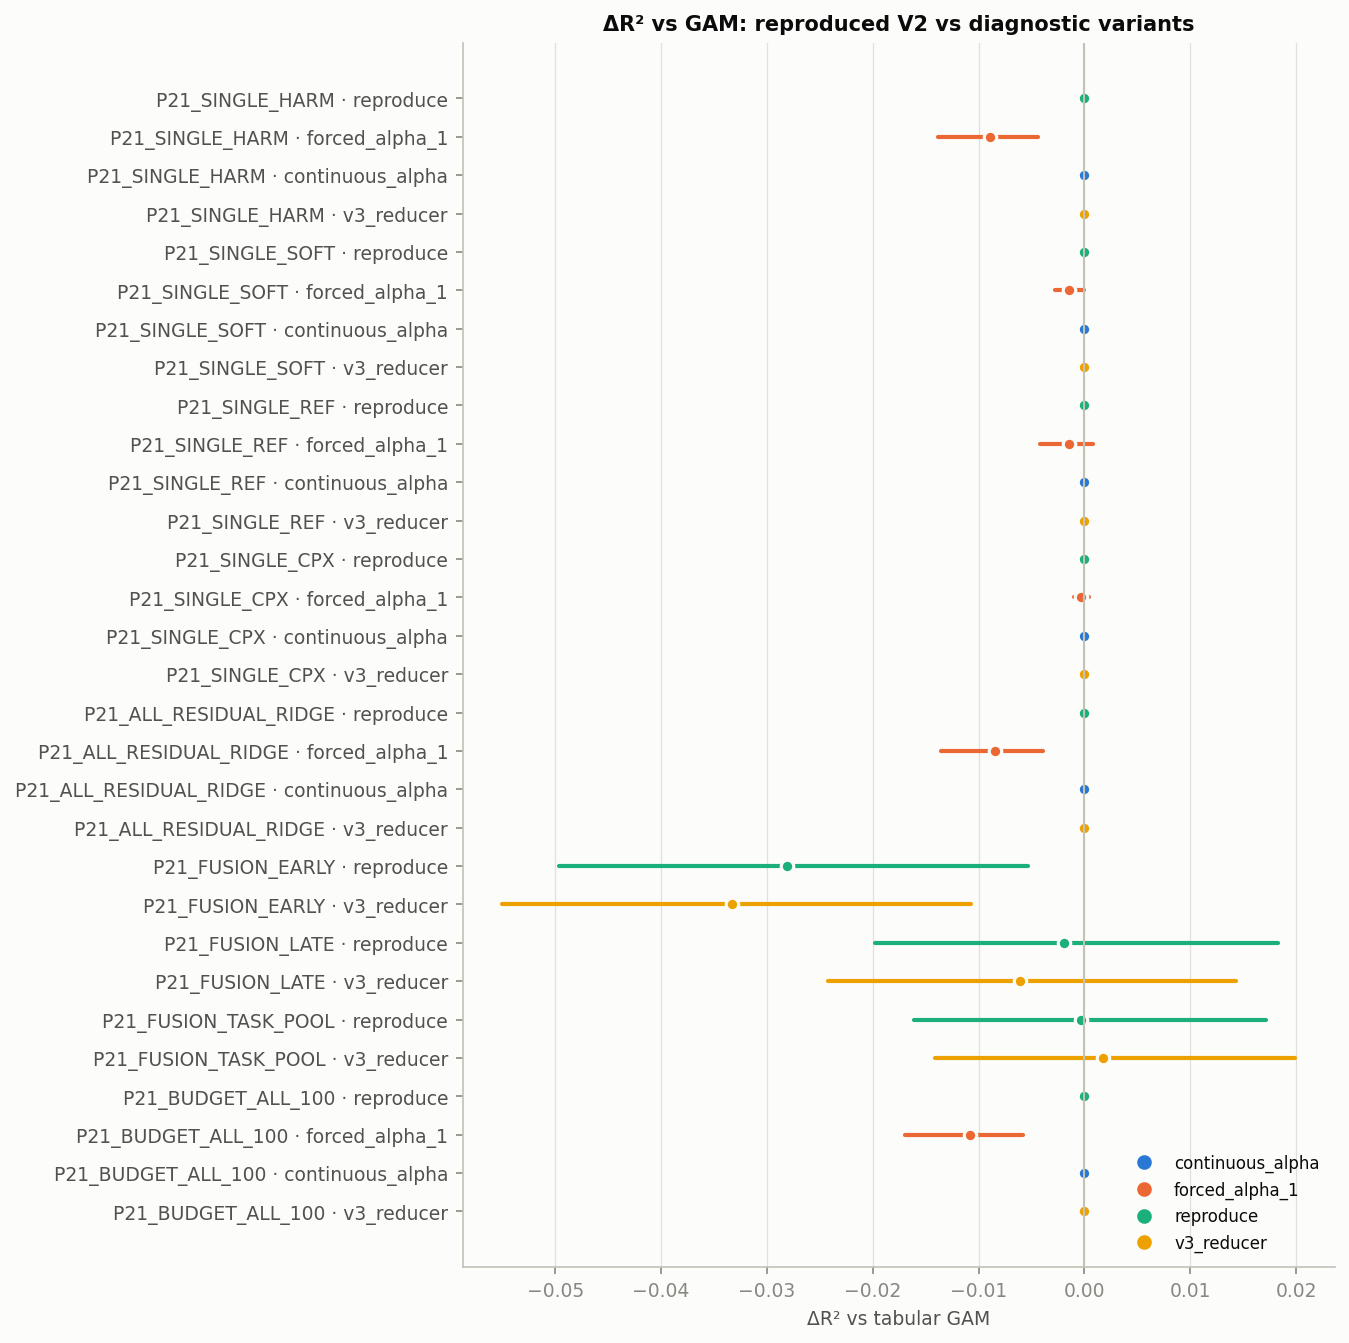

residual_alpha_by_fold.png


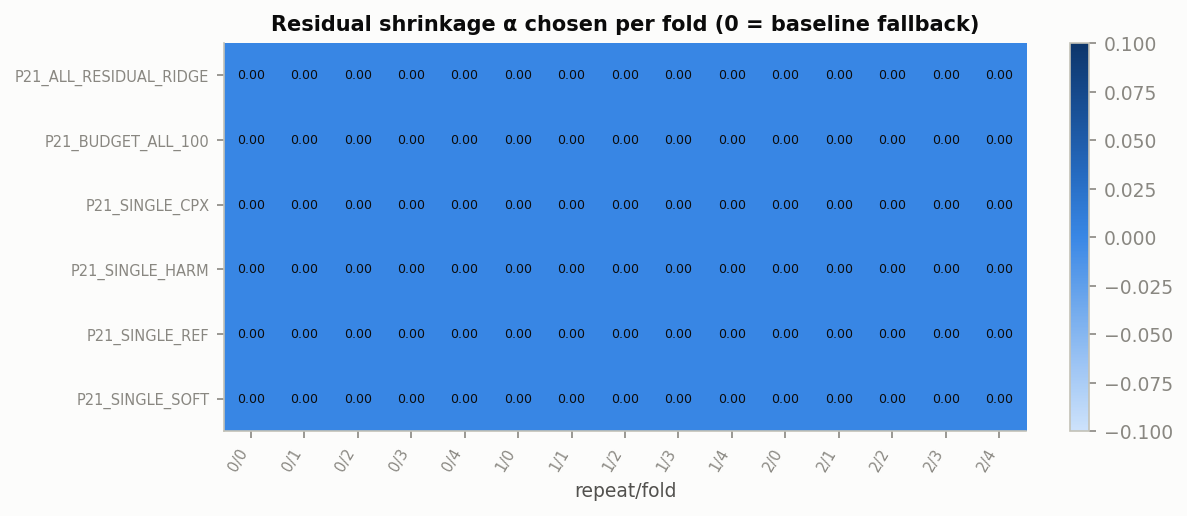

stage2_prediction_sd.png


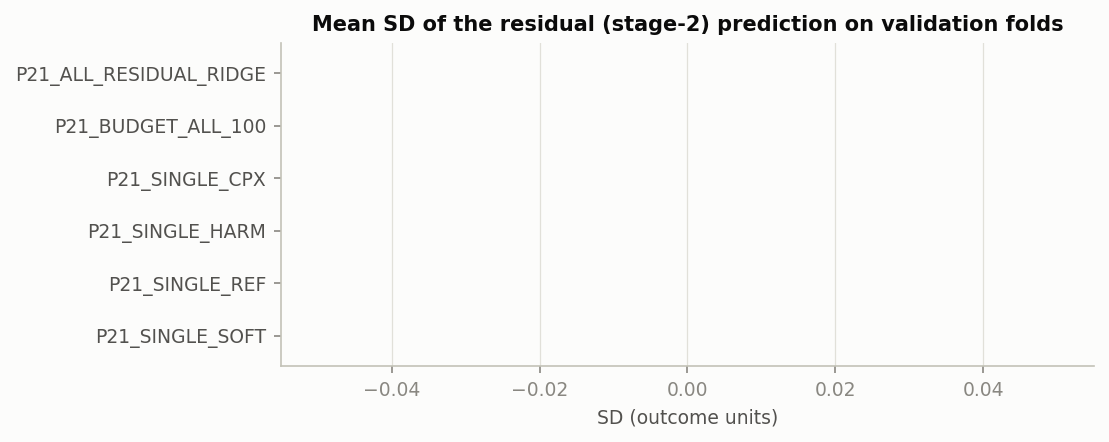

task_ensemble_extremes.png


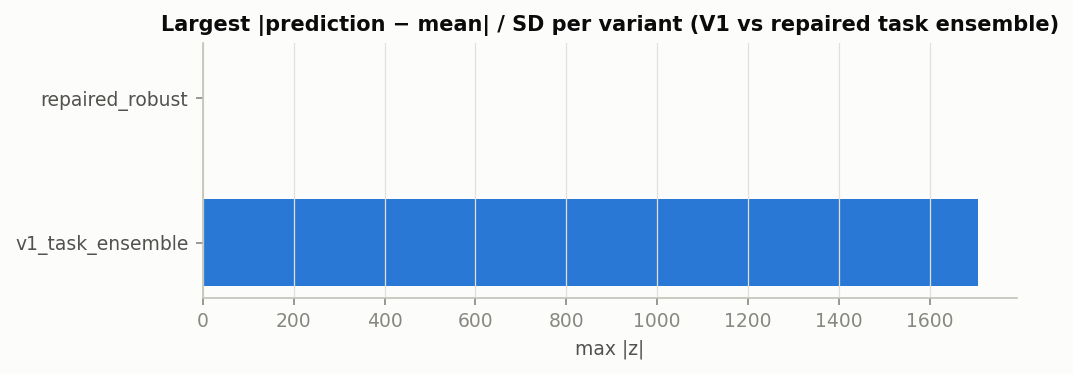

v2_budget_cap.png


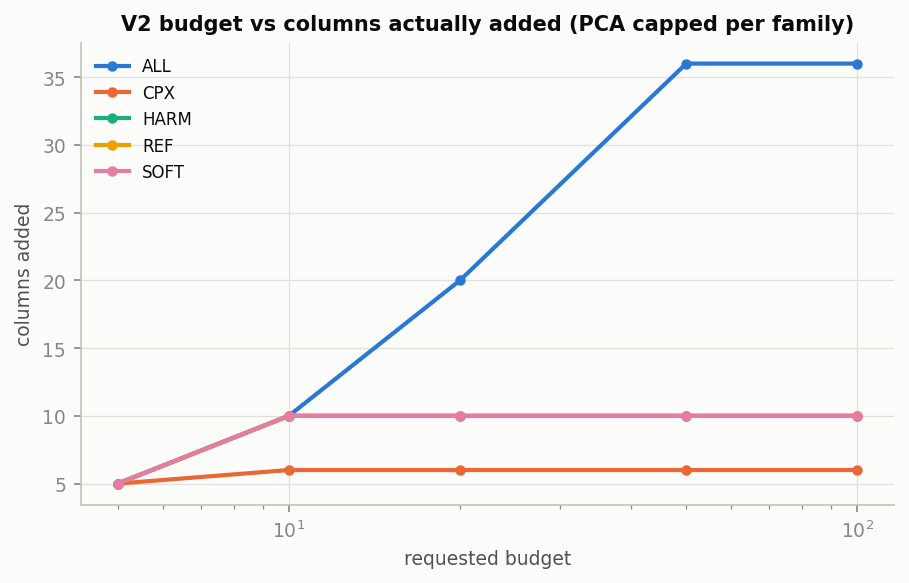

In [5]:
for t in ("baseline_reproduction", "fusion_verdicts", "v2_budget_cap", "task_ensemble_summary", "lineage_audit", "v3_repairs"):
    df = nb.table(ctx, "P23", t, n=None)
    if df is not None:
        print(f"--- {t}"); display(df)
nb.show_figures(ctx, "P23")

## 1. Environment and GPU diagnostics
Package versions, CUDA, VRAM, bf16, `.bin` loadability (transformers ≥ 4.50 refuses `torch.load` on torch < 2.6 → verified safetensors conversion), hf_xet, qwen_asr/vLLM.

In [6]:
env = nb.environment()
display(env)
if not bool(env.loc["cuda_available", "value"]):
    display(Markdown("**CUDA not available** — GPU inference will not be READY (see gpu_readiness)."))
if not bool(env.loc["bin_weights_loadable", "value"]):
    display(Markdown("`.bin`-only checkpoints (espeak phoneme, wav2vec2-base, HuBERT, WavLM) are converted to a "
                     "**sha256-verified local safetensors copy** at install time; torch is not upgraded."))

c:\Users\myben\.conda\envs\MITSUI\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,value
python,3.10.18
platform,win32
torch_ok,True
torch_version,2.5.1+cu124
torchaudio_ok,True
torchaudio_version,2.5.1+cu124
transformers_ok,True
transformers_version,4.57.6
accelerate_ok,True
accelerate_version,1.15.0


`.bin`-only checkpoints (espeak phoneme, wav2vec2-base, HuBERT, WavLM) are converted to a **sha256-verified local safetensors copy** at install time; torch is not upgraded.

## 2. Model eligibility (13 dimensions → lifecycle)
Live, from local files only. Pending reviews show the exact `accept-proposal` / `record` command; overlap approvals need a positive basis (absence of known overlap is refused). **Pasketti:** the cards list *ReadNet* (Reach Every Reader data) among training corpora — overlap with these children is likely; the drafts are `ready: false` until you decide.

In [7]:
rep = nb.eligibility_report(ctx, deep=DEEP_CHECK, verify_hashes=VERIFY_HASHES)
display(rep["summary"])
nb.show_eligibility_matrix(ctx, rep=rep)
display(rep["dimensions"].pivot(index="model_key", columns="dimension", values="status"))

c:\Users\myben\.conda\envs\MITSUI\lib\site-packages\transformers\configuration_utils.py:335: UserWarning: Passing `gradient_checkpointing` to a config initialization is deprecated and will be removed in v5 Transformers. Using `model.gradient_checkpointing_enable()` instead, or if you are using the `Trainer` API, pass `gradient_checkpointing=True` in your `TrainingArguments`.
  warnings.warn(


,model_key,priority,family,role,output,lifecycle,eligible,download_allowed,legal_status,provenance_status,checkpoint_status,framework_status,architecture,snapshot_origin,snapshot_kind,snapshot_revision,license,gpu_need_gb,manifest_gb
0,pasketti_phonetic,1,pasketti,child_phonetic,phones,LEGAL_REVIEW_PENDING,False,False,PENDING_REVIEW,PENDING_REVIEW,FAIL,NOT_PROBED,unknown,None,None,None,bigcode-openrail-m,NaN,1.262
1,whisper_small_en,2,whisper,general_word,words,LEGAL_REVIEW_PENDING,False,False,PENDING_REVIEW,PENDING_REVIEW,FAIL,NOT_PROBED,unknown,None,None,None,apache-2.0,NaN,0.971
2,pasketti_word,3,pasketti,child_word,words,LEGAL_REVIEW_PENDING,False,False,PENDING_REVIEW,PENDING_REVIEW,FAIL,NOT_PROBED,unknown,None,None,None,bigcode-openrail-m,NaN,4.092
3,wav2vec2_phoneme_espeak,4,wav2vec2,general_phonetic,phones,LEGAL_REVIEW_PENDING,False,False,PENDING_REVIEW,PENDING_REVIEW,FAIL,NOT_PROBED,unknown,None,None,None,apache-2.0,NaN,1.264
4,wav2vec2_base_960h,5,wav2vec2,general_char,chars,LEGAL_REVIEW_PENDING,False,False,PENDING_REVIEW,PENDING_REVIEW,PASS,PASS,hf_ctc,hf_cache,hf_cache,22aad52d435eb6dbaf354bdad9b0da84ce7d6156,apache-2.0,1.34,0.378
5,wav2vec2_base,6,wav2vec2,frozen_encoder,embeddings,LEGAL_REVIEW_PENDING,False,False,PENDING_REVIEW,PENDING_REVIEW,FAIL,FAIL,hf_encoder,hf_cache,hf_cache,0b5b8e868dd84f03fd87d01f9c4ff0f080fecfe8,apache-2.0,1.34,0.380
6,hubert_base,7,hubert,frozen_encoder,embeddings,LEGAL_REVIEW_PENDING,False,False,PENDING_REVIEW,PENDING_REVIEW,FAIL,NOT_PROBED,unknown,None,None,None,apache-2.0,NaN,0.378
7,wavlm_base_plus,8,wavlm,frozen_encoder,embeddings,LEGAL_REVIEW_PENDING,False,False,PENDING_REVIEW,PENDING_REVIEW,FAIL,NOT_PROBED,unknown,None,None,None,cc-by-sa-3.0,NaN,0.378


<Figure size 965x560 with 1 Axes>

<Figure size 1100x480 with 1 Axes>

dimension,architecture_compatibility,checkpoint_availability,checkpoint_files,competition_permission,framework_dependencies,gpu_readiness,inference_readiness,license_approval,license_documentation,overlap_assessment,processor_compatibility,registry_validity,training_provenance
model_key,,,,,,,,,,,,,
hubert_base,NOT_PROBED,FAIL,NOT_PROBED,PASS,NOT_PROBED,NOT_PROBED,NOT_PROBED,PENDING,PASS,PENDING,NOT_PROBED,PASS,PENDING
pasketti_phonetic,NOT_PROBED,FAIL,NOT_PROBED,PASS,NOT_PROBED,NOT_PROBED,NOT_PROBED,PENDING,PASS,PENDING,NOT_PROBED,PASS,PENDING
pasketti_word,NOT_PROBED,FAIL,NOT_PROBED,PASS,NOT_PROBED,NOT_PROBED,NOT_PROBED,PENDING,PASS,PENDING,NOT_PROBED,PASS,PENDING
wav2vec2_base,PASS,PASS,FAIL,PASS,FAIL,PASS,NOT_PROBED,PENDING,PASS,PENDING,FAIL,PASS,PENDING
wav2vec2_base_960h,PASS,PASS,PASS,PASS,PASS,PASS,NOT_PROBED,PENDING,PASS,PENDING,PASS,PASS,PENDING
wav2vec2_phoneme_espeak,NOT_PROBED,FAIL,NOT_PROBED,PASS,NOT_PROBED,NOT_PROBED,NOT_PROBED,PENDING,PASS,PENDING,NOT_PROBED,PASS,PENDING
wavlm_base_plus,NOT_PROBED,FAIL,NOT_PROBED,PENDING,NOT_PROBED,NOT_PROBED,NOT_PROBED,PENDING,PASS,PENDING,NOT_PROBED,PASS,PENDING
whisper_small_en,NOT_PROBED,FAIL,NOT_PROBED,PASS,NOT_PROBED,NOT_PROBED,NOT_PROBED,PENDING,PASS,PENDING,NOT_PROBED,PASS,PENDING


In [8]:
acts = rep["actions"]
print("REQUIRED ACTIONS" if not acts.empty else "no outstanding actions")
if not acts.empty:
    display(acts.sort_values(["priority", "model_key", "step"]))
print("--- review proposals (drafts; approve nothing until accepted under your name)")
display(rep["proposals"])
for k in ("restrictions", "policy", "license_policy", "invalid_reviews", "evidence"):
    if k in rep and rep[k] is not None and not rep[k].empty:
        print(f"--- {k}"); display(rep[k])

REQUIRED ACTIONS


,model_key,priority,lifecycle,step,action
0,pasketti_phonetic,1,LEGAL_REVIEW_PENDING,1,"python -m wildspeech.asr.reviews accept-proposal --id P-PSKPH-L --reviewer ""<your name>"" (draft in configs/v3_asr_r..."
1,pasketti_phonetic,1,LEGAL_REVIEW_PENDING,2,"python -m wildspeech.asr.reviews accept-proposal --id P-PSKPH-P --reviewer ""<your name>"" (draft in configs/v3_asr_r..."
2,pasketti_phonetic,1,LEGAL_REVIEW_PENDING,3,"python -m wildspeech.asr.reviews accept-proposal --id P-PSKPH-OV --reviewer ""<your name>"" (draft in configs/v3_asr_..."
3,pasketti_phonetic,1,LEGAL_REVIEW_PENDING,4,python -m wildspeech v3-install --model pasketti_phonetic --execute
4,pasketti_phonetic,1,LEGAL_REVIEW_PENDING,5,python -m wildspeech v3-smoke --model pasketti_phonetic
5,whisper_small_en,2,LEGAL_REVIEW_PENDING,1,"python -m wildspeech.asr.reviews accept-proposal --id P-WSP-LP --reviewer ""<your name>"" (draft in configs/v3_asr_re..."
6,whisper_small_en,2,LEGAL_REVIEW_PENDING,2,"python -m wildspeech.asr.reviews accept-proposal --id P-WSP-OV --reviewer ""<your name>"" (draft in configs/v3_asr_re..."
7,whisper_small_en,2,LEGAL_REVIEW_PENDING,3,python -m wildspeech v3-install --model whisper_small_en --execute
8,whisper_small_en,2,LEGAL_REVIEW_PENDING,4,python -m wildspeech v3-smoke --model whisper_small_en
9,pasketti_word,3,LEGAL_REVIEW_PENDING,1,"python -m wildspeech.asr.reviews accept-proposal --id P-PSKWD-L --reviewer ""<your name>"" (draft in configs/v3_asr_r..."


--- review proposals (drafts; approve nothing until accepted under your name)


,proposal_id,model_key,checks,decision,ready,overlap_basis,acknowledged_conditions,resolves,open_questions,prepared_by,prepared_on
0,P-WSP-LP,whisper_small_en,"license,provenance",approved,True,None,,,,Claude (assistant draft),2026-11-21
1,P-WSP-OV,whisper_small_en,overlap,approved,True,temporal_precedence,,WSP-OVERLAP,,Claude (assistant draft),2026-11-21
2,P-ESP-LP,wav2vec2_phoneme_espeak,"license,provenance",approved,True,None,,,,Claude (assistant draft),2026-11-21
3,P-ESP-OV,wav2vec2_phoneme_espeak,overlap,approved,True,enumerated_public_corpora_disjoint,,,,Claude (assistant draft),2026-11-21
4,P-B960-LP,wav2vec2_base_960h,"license,provenance",approved,True,None,,,,Claude (assistant draft),2026-11-21
5,P-B960-OV,wav2vec2_base_960h,overlap,approved,True,enumerated_public_corpora_disjoint,,,,Claude (assistant draft),2026-11-21
6,P-W2VB-LP,wav2vec2_base,"license,provenance",approved,True,None,,,,Claude (assistant draft),2026-11-21
7,P-W2VB-OV,wav2vec2_base,overlap,approved,True,enumerated_public_corpora_disjoint,,,,Claude (assistant draft),2026-11-21
8,P-HUB-LP,hubert_base,"license,provenance",approved,True,None,,,,Claude (assistant draft),2026-11-21
9,P-HUB-OV,hubert_base,overlap,approved,True,enumerated_public_corpora_disjoint,,,,Claude (assistant draft),2026-11-21


--- restrictions


,model_key,id,check,text,blocking
0,pasketti_phonetic,PSK-PH-LICENSE,license,"bigcode-openrail-m is a conditional license (use restrictions, not OSI). Approve only with every condition of licens...",True
1,pasketti_phonetic,PSK-PH-READNET-OVERLAP,overlap,"The card names ""ReadNet"" among the phonetic training corpora. This competition's audio comes from the Reach Every Re...",True
2,whisper_small_en,WSP-OVERLAP,overlap,"The web training set is not enumerated, so overlap cannot be ruled out by listing corpora. A positive basis is requi...",True
3,pasketti_word,PSK-WD-LICENSE,license,bigcode-openrail-m: conditional license; acknowledge every condition.,True
4,pasketti_word,PSK-WD-READNET-OVERLAP,overlap,"Same as PSK-PH-READNET-OVERLAP: ""ReadNet"" (Reach Every Reader data) is a named training corpus and one in-classroom ...",True
5,wavlm_base_plus,WLM-LICENSE,license,License of the weights is not stated on the model card (see license_policy.conditional.cc-by-sa-3.0). Approve only a...,True


... (2 outputs left out)

--- license_policy


,license_id,class,conditions
0,apache-2.0,permissive,
1,mit,permissive,
2,bsd-2-clause,permissive,
3,bsd-3-clause,permissive,
4,cc0-1.0,permissive,
5,cc-by-4.0,permissive,
6,bigcode-openrail-m,openrail_use_restricted,OPENRAIL-USE-RESTRICTIONS: Attachment A use-based restrictions apply to the model and every derivative (e.g. no use ...
7,cc-by-sa-3.0,share_alike,CC-BY-SA-SHAREALIKE: Attribution + ShareAlike: adaptations of the licensed material must carry the same license. Com...
8,cc-by-nc-4.0,prohibited,
9,cc-by-nc-sa-4.0,prohibited,


--- evidence


,model_key,hf_id,revision,evidence_status,model_card_url,license_id,license_url,license_evidence,training_sources,training_evidence_url,enumerated_corpora,release_date,architecture_evidence,output_format,reported_metrics,notes,link_api_url,link_collection_url,link_announcement_url,link_paper_url
0,pasketti_phonetic,drivendata/pasketti-phonetic,675dfe392a2af7050f1374eeab4458cb1f003b3e,assembled_from_official_sources,https://huggingface.co/drivendata/pasketti-phonetic,bigcode-openrail-m,https://www.bigcode-project.org/docs/pages/bigcode-openrail/,cardData.license = bigcode-openrail-m; tag license:bigcode-openrail-m (HF API at 675dfe3).,"116 h of phonetically transcribed child speech, ~1,700 children (card) | Phonetic training corpora (card): Arizona C...",https://huggingface.co/drivendata/pasketti-phonetic,True,None,"config.architectures = [WavLMForCTC], model_type = wavlm; card: 'a standard transformers WavLMForCTC'; no auto_map (...","IPA characters (CTC); greedy decoding as evaluated on the card; mapped to ARPAbet for features, raw IPA kept",PER 33% overall on 44 h / 737 held-out children (card),Card pins transformers==4.57.6 (matches MITSUI). torch 2.6 on the card; safetensors weights load on torch 2.5.1.,https://huggingface.co/api/models/drivendata/pasketti-phonetic,https://huggingface.co/collections/drivendata/pasketti,https://blog.drivendata.org/blog/on-top-of-pasketti-winners,NaN
1,whisper_small_en,openai/whisper-small.en,e8727524f962ee844a7319d92be39ac1bd25655a,assembled_from_official_sources,https://huggingface.co/openai/whisper-small.en,apache-2.0,https://huggingface.co/openai/whisper-small.en,cardData.license = apache-2.0; tag license:apache-2.0 (HF API at e872752).,"680,000 hours of audio and transcripts collected from the internet (card, verbatim); English portion for .en",https://arxiv.org/abs/2212.04356,False,2022-09-26,config.architectures = [WhisperForConditionalGeneration]; no auto_map.,English words (BPE) with real token log-probabilities,None,Card: hallucination/repetition risk; 'We recommend against use in high-risk domains like decision-making contexts.',https://huggingface.co/api/models/openai/whisper-small.en,NaN,NaN,https://arxiv.org/abs/2212.04356
2,pasketti_word,drivendata/pasketti-word,7756647568342982e5f9777f1c34fdcd5fa59866,assembled_from_official_sources,https://huggingface.co/drivendata/pasketti-word,bigcode-openrail-m,https://www.bigcode-project.org/docs/pages/bigcode-openrail/,cardData.license = bigcode-openrail-m; tag license:bigcode-openrail-m (HF API at 7756647).,"372 h of child speech from >3,600 children, 12 source corpora (card) | Named corpora (card): Arizona Child Acoustic ...",https://huggingface.co/drivendata/pasketti-word,partial,None,"config.architectures = [Qwen3ASRForConditionalGeneration], model_type = qwen3_asr; card: Qwen3ASRModel.LLM(...) via ...",orthographic words; no token probabilities exposed by the qwen_asr transcribe API,"WER 17% overall on 148 h / >2,300 held-out children (card)",None,https://huggingface.co/api/models/drivendata/pasketti-word,https://huggingface.co/collections/drivendata/pasketti,https://blog.drivendata.org/blog/on-top-of-pasketti-winners,NaN
3,wav2vec2_phoneme_espeak,facebook/wav2vec2-lv-60-espeak-cv-ft,ae45363bf3413b374fecd9dc8bc1df0e24c3b7f4,assembled_from_official_sources,https://huggingface.co/facebook/wav2vec2-lv-60-espeak-cv-ft,apache-2.0,https://huggingface.co/facebook/wav2vec2-lv-60-espeak-cv-ft,cardData.license = apache-2.0; tag license:apache-2.0 (HF API at ae45363).,"Pretrained wav2vec2-large-lv60 (Libri-Light, ~60k h of public-domain English audiobooks) | Fine-tuned on Common Voic...",https://arxiv.org/abs/2109.11680,True,2022-03-02,config.architectures = [Wav2Vec2ForCTC]; no auto_map.,eSpeak IPA phone tokens (used with do_phonemize=False),None,"Only pytorch_model.bin is published: transformers 4.57 refuses torch.load on torch < 2.6, so the manager converts th...",https://huggingface.co/api/models/facebook/wav2vec2-lv-60-espeak-cv-ft,NaN,N

**Recording approvals (run in a terminal, never from this notebook):**
```powershell
python -m wildspeech.asr.reviews proposals
python -m wildspeech.asr.reviews accept-proposal --id P-WSP-LP P-WSP-OV P-B960-LP P-B960-OV --reviewer "<your full name>"
python -m wildspeech.asr.reviews accept-proposal --id P-PSKPH-L P-PSKPH-P P-PSKPH-OV --reviewer "<your full name>" --resolved-open-questions --mitigation "<your words>"
python -m wildspeech.asr.reviews show
```

## 3. Download and checkpoint status
Complete HF-cache snapshots at the pinned commit are used in place (e.g. wav2vec2-base-960h); partial ones are completed in the cache; others go to `models/<dir>/` as real files. Only APPROVED models are installed, and only when `ALLOW_MODEL_DOWNLOADS = True`.

In [9]:
display(nb.installed_checkpoints(ctx))
plan = nb.install_plan(ctx)
display(plan)
print(f"to download: {plan['download_gb'].sum():.2f} GB | conversions: {int(plan['conversion_needed'].sum())}")

,model_key,installed,origin,kind,path,revision,revision_source,pinned,architecture,manifest_gb,problems,searched
0,pasketti_phonetic,False,None,None,None,None,None,675dfe392a2af7050f1374eeab4458cb1f003b3e,None,1.262,checkpoint not on disk at pinned revision 675dfe392a2af7050f1374eeab4458cb1f003b3e (searched: C:\Users\myben\Downloa...,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\pasketti_phonetic; C:\Users\myben\.cache\huggingface\hub
1,whisper_small_en,False,None,None,None,None,None,e8727524f962ee844a7319d92be39ac1bd25655a,None,0.971,checkpoint not on disk at pinned revision e8727524f962ee844a7319d92be39ac1bd25655a (searched: C:\Users\myben\Downloa...,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\whisper_small_en; C:\Users\myben\.cache\huggingface\hub
2,pasketti_word,False,None,None,None,None,None,7756647568342982e5f9777f1c34fdcd5fa59866,None,4.092,checkpoint not on disk at pinned revision 7756647568342982e5f9777f1c34fdcd5fa59866 (searched: C:\Users\myben\Downloa...,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\pasketti_word; C:\Users\myben\.cache\huggingface\hub
3,wav2vec2_phoneme_espeak,False,None,None,None,None,None,ae45363bf3413b374fecd9dc8bc1df0e24c3b7f4,None,1.264,checkpoint not on disk at pinned revision ae45363bf3413b374fecd9dc8bc1df0e24c3b7f4 (searched: C:\Users\myben\Downloa...,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wav2vec2_phoneme; C:\Users\myben\.cache\huggingface\hub
4,wav2vec2_base_960h,True,hf_cache,hf_cache,C:\Users\myben\.cache\huggingface\hub\models--facebook--wav2vec2-base-960h\snapshots\22aad52d435eb6dbaf354bdad9b0da8...,22aad52d435eb6dbaf354bdad9b0da84ce7d6156,hf_cache_path,22aad52d435eb6dbaf354bdad9b0da84ce7d6156,hf_ctc,0.378,,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wav2vec2_base_960h; C:\Users\myben\.cache\huggingface\hub
5,wav2vec2_base,False,hf_cache,hf_cache,C:\Users\myben\.cache\huggingface\hub\models--facebook--wav2vec2-base\snapshots\0b5b8e868dd84f03fd87d01f9c4ff0f080fe...,0b5b8e868dd84f03fd87d01f9c4ff0f080fecfe8,hf_cache_path,0b5b8e868dd84f03fd87d01f9c4ff0f080fecfe8,hf_encoder,0.380,missing preprocessor_config.json,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wav2vec2_base; C:\Users\myben\.cache\huggingface\hub
6,hubert_base,False,None,None,None,None,None,dba3bb02fda4248b6e082697eee756de8fe8aa8a,None,0.378,checkpoint not on disk at pinned revision dba3bb02fda4248b6e082697eee756de8fe8aa8a (searched: C:\Users\myben\Downloa...,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\hubert_base; C:\Users\myben\.cache\huggingface\hub
7,wavlm_base_plus,False,None,None,None,None,None,4c66d4806a428f2e922ccfa1a962776e232d487b,None,0.378,checkpoint not on disk at pinned revision 4c66d4806a428f2e922ccfa1a962776e232d487b (searched: C:\Users\myben\Downloa...,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wavlm_base_plus; C:\Users\myben\.cache\huggingface\hub


,model_key,hf_id,revision,storage,path,local_dir,lifecycle,download_allowed,manifest_files,present_files,missing_files,download_bytes,download_gb,conversion_needed,conversion_note,conversion_gb,disk_free_gb,disk_ok
0,pasketti_phonetic,drivendata/pasketti-phonetic,675dfe392a2af7050f1374eeab4458cb1f003b3e,local_dir,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\pasketti_phonetic,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\pasketti_phonetic,LEGAL_REVIEW_PENDING,False,7,0,"config.json,preprocessor_config.json,vocab.json,tokenizer_config.json,special_tokens_map.json,added_tokens.json,mode...",1262101875,1.262,False,,0.000,361.46,True
1,whisper_small_en,openai/whisper-small.en,e8727524f962ee844a7319d92be39ac1bd25655a,local_dir,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\whisper_small_en,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\whisper_small_en,LEGAL_REVIEW_PENDING,False,11,0,"config.json,generation_config.json,preprocessor_config.json,tokenizer.json,tokenizer_config.json,vocab.json,merges.t...",970930930,0.971,False,,0.000,361.46,True
2,pasketti_word,drivendata/pasketti-word,7756647568342982e5f9777f1c34fdcd5fa59866,local_dir,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\pasketti_word,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\pasketti_word,LEGAL_REVIEW_PENDING,False,11,0,"config.json,generation_config.json,preprocessor_config.json,chat_template.json,tokenizer.json,tokenizer_config.json,...",4092092591,4.092,False,,0.000,361.46,True
3,wav2vec2_phoneme_espeak,facebook/wav2vec2-lv-60-espeak-cv-ft,ae45363bf3413b374fecd9dc8bc1df0e24c3b7f4,local_dir,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wav2vec2_phoneme,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wav2vec2_phoneme,LEGAL_REVIEW_PENDING,False,6,0,"config.json,preprocessor_config.json,vocab.json,tokenizer_config.json,special_tokens_map.json,pytorch_model.bin",1263542238,1.264,True,transformers 4.57.6 refuses torch.load of .bin weights with torch 2.5.1+cu124 < 2.6 (CVE-2025-32434); use the sha256...,1.264,361.46,True
4,wav2vec2_base_960h,facebook/wav2vec2-base-960h,22aad52d435eb6dbaf354bdad9b0da84ce7d6156,hf_cache_in_place,C:\Users\myben\.cache\huggingface\hub\models--facebook--wav2vec2-base-960h\snapshots\22aad52d435eb6dbaf354bdad9b0da8...,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wav2vec2_base_960h,LEGAL_REVIEW_PENDING,False,6,6,,0,0.000,False,,0.000,361.46,True
5,wav2vec2_base,facebook/wav2vec2-base,0b5b8e868dd84f03fd87d01f9c4ff0f080fecfe8,hf_cache,C:\Users\myben\.cache\huggingface\hub\models--facebook--wav2vec2-base\snapshots\0b5b8e868dd84f03fd87d01f9c4ff0f080fe...,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wav2vec2_base,LEGAL_REVIEW_PENDING,False,3,2,preprocessor_config.json,159,0.000,True,transformers 4.57.6 refuses torch.load of .bin weights with torch 2.5.1+cu124 < 2.6 (CVE-2025-32434); use the sha256...,0.380,361.46,True
6,hubert_base,facebook/hubert-base-ls960,dba3bb02fda4248b6e082697eee756de8fe8aa8a,local_dir,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\hubert_base,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\hubert_base,LEGAL_REVIEW_PENDING,False,3,0,"config.json,preprocessor_config.json,pytorch_model.bin",377571352,0.378,True,transformers 4.57.6 refuses torch.load of .bin weights with torch 2.5.1+cu124 < 2.6 (CVE-2025-32434); use the sha256...,0.378,361.46,True
7,wavlm_base_plus,microsoft/wavlm-base-plus,4c66d4806a428f2e922ccfa1a962776e232d487b,local_dir,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wavlm_base_plus,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wavlm_base_plus,LEGAL_REVIEW_PENDING,False,3,0,"config.json,preprocessor_config.json,pytorch_model.bin",377619872,0.378,True,transformers 4.57.6 refuses torch.load of .bin weights with torch 2.5.1+cu124 < 2.6 (CVE-2025-32434); use the sha256...,0.378,361.46,True


to download: 8.35 GB | conversions: 4


In [10]:
res = nb.install(ctx, allow=ALLOW_MODEL_DOWNLOADS, verify=True)   # allow=False -> dry run, nothing downloaded
display(res[[c for c in ("model_key", "lifecycle", "action", "storage", "path", "download_gb", "ok", "error") if c in res]])
if VERIFY_HASHES:
    display(nb.verify(ctx))

,model_key,lifecycle,action,storage,path,download_gb,ok,error
0,pasketti_phonetic,LEGAL_REVIEW_PENDING,blocked_by_eligibility,local_dir,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\pasketti_phonetic,1.262,False,lifecycle LEGAL_REVIEW_PENDING: reviews must pass before any download
1,whisper_small_en,LEGAL_REVIEW_PENDING,blocked_by_eligibility,local_dir,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\whisper_small_en,0.971,False,lifecycle LEGAL_REVIEW_PENDING: reviews must pass before any download
2,pasketti_word,LEGAL_REVIEW_PENDING,blocked_by_eligibility,local_dir,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\pasketti_word,4.092,False,lifecycle LEGAL_REVIEW_PENDING: reviews must pass before any download
3,wav2vec2_phoneme_espeak,LEGAL_REVIEW_PENDING,blocked_by_eligibility,local_dir,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wav2vec2_phoneme,1.264,False,lifecycle LEGAL_REVIEW_PENDING: reviews must pass before any download
4,wav2vec2_base_960h,LEGAL_REVIEW_PENDING,blocked_by_eligibility,hf_cache_in_place,C:\Users\myben\.cache\huggingface\hub\models--facebook--wav2vec2-base-960h\snapshots\22aad52d435eb6dbaf354bdad9b0da8...,0.000,False,lifecycle LEGAL_REVIEW_PENDING: reviews must pass before any download
5,wav2vec2_base,LEGAL_REVIEW_PENDING,blocked_by_eligibility,hf_cache,C:\Users\myben\.cache\huggingface\hub\models--facebook--wav2vec2-base\snapshots\0b5b8e868dd84f03fd87d01f9c4ff0f080fe...,0.000,False,lifecycle LEGAL_REVIEW_PENDING: reviews must pass before any download
6,hubert_base,LEGAL_REVIEW_PENDING,blocked_by_eligibility,local_dir,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\hubert_base,0.378,False,lifecycle LEGAL_REVIEW_PENDING: reviews must pass before any download
7,wavlm_base_plus,LEGAL_REVIEW_PENDING,blocked_by_eligibility,local_dir,C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\models\wavlm_base_plus,0.378,False,lifecycle LEGAL_REVIEW_PENDING: reviews must pass before any download


## 4. Model-loading diagnostics
Processor / tokenizer contract (no weights), then an optional few-clip smoke decode per READY model (one GPU model at a time; results feed `inference_readiness`).

In [11]:
display(nb.component_checks(ctx))
if RUN_SMOKE:
    sm = nb.smoke(ctx, clips=8)
    display(sm)
    for k in sm.loc[sm["ok"].astype(bool), "model_key"]:
        print(f"--- {k}"); display(nb.smoke_examples(ctx, k))
else:
    print("RUN_SMOKE is False -> no weights loaded")

c:\Users\myben\.conda\envs\MITSUI\lib\site-packages\transformers\configuration_utils.py:335: UserWarning: Passing `gradient_checkpointing` to a config initialization is deprecated and will be removed in v5 Transformers. Using `model.gradient_checkpointing_enable()` instead, or if you are using the `Trainer` API, pass `gradient_checkpointing=True` in your `TrainingArguments`.
  warnings.warn(


,model_key,architecture,path,ok,problems,notes,model_type,architectures,sampling_rate,vocab_size,tokenizer_class,feat_extract_norm,return_attention_mask,pad_token,word_delimiter,letters
0,wav2vec2_base_960h,hf_ctc,C:\Users\myben\.cache\huggingface\hub\models--facebook--wav2vec2-base-960h\snapshots\22aad52d435eb6dbaf354bdad9b0da8...,True,,,wav2vec2,Wav2Vec2ForCTC,16000.0,32.0,Wav2Vec2CTCTokenizer,group,False,<pad>,|,26.0
1,wav2vec2_base,hf_encoder,C:\Users\myben\.cache\huggingface\hub\models--facebook--wav2vec2-base\snapshots\0b5b8e868dd84f03fd87d01f9c4ff0f080fe...,False,OSError: Can't load feature extractor for 'C:\Users\myben\.cache\huggingface\hub\models--facebook--wav2vec2-base\sna...,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


RUN_SMOKE is False -> no weights loaded


## 5. ASR inference (P24)
Eligibility → gated install → smoke → resumable inference (priority order, duration-aware batches, OOM halving, fp16/bf16 guard, CPU fallback, Parquet checkpoints). Live tqdm shows %, ETA, clips/s, RAM, VRAM and failures. Interrupting is safe: finished clips are flushed and resume skips them.

In [12]:
display(nb.run_stages(ctx, ["P24"], FORCE, enabled=RUN_PIPELINE))
out = nb.p24_outcome(ctx)
print("P24 outcome:", out.get("stage_outcome"), "| inference_executed:", out.get("inference_executed"))
print("lifecycle:", out.get("lifecycle_after") or out.get("lifecycle"))

RUN_PIPELINE is False -> showing the plan only (nothing executed)


,stage,status,note
0,P24,would_run,"eligible local child/general ASR inference (resumable, provenance-tracked)"


P24 outcome: ELIGIBILITY_ONLY | inference_executed: False
lifecycle: {'pasketti_phonetic': 'LEGAL_REVIEW_PENDING', 'whisper_small_en': 'LEGAL_REVIEW_PENDING', 'pasketti_word': 'LEGAL_REVIEW_PENDING', 'wav2vec2_phoneme_espeak': 'LEGAL_REVIEW_PENDING', 'wav2vec2_base_960h': 'LEGAL_REVIEW_PENDING', 'wav2vec2_base': 'LEGAL_REVIEW_PENDING', 'hubert_base': 'LEGAL_REVIEW_PENDING', 'wavlm_base_plus': 'LEGAL_REVIEW_PENDING'}


In [13]:
display(nb.execution_state(ctx))
display(nb.coverage_figure(ctx))
for t in ("not_executed", "install_results", "smoke_tests", "inference_runs", "throughput", "asr_outputs_inventory",
          "model_eligibility_after"):
    df = nb.table(ctx, "P24", t, n=None)
    if df is not None:
        print(f"--- {t}"); display(df)

,model_key,split,state,rows,failures,candidates,coverage,origin,accepted
0,pasketti_phonetic,train,rejected,0,0,14704,0.0,none,False
1,whisper_small_en,train,rejected,0,0,14704,0.0,none,False
2,pasketti_word,train,rejected,0,0,14704,0.0,none,False
3,wav2vec2_phoneme_espeak,train,rejected,0,0,14704,0.0,none,False
4,wav2vec2_base_960h,train,rejected,0,0,14704,0.0,none,False
5,wav2vec2_base,train,never_run,0,0,14704,0.0,none,False
6,hubert_base,train,never_run,0,0,14704,0.0,none,False
7,wavlm_base_plus,train,never_run,0,0,14704,0.0,none,False


<Figure size 700x340 with 1 Axes>

--- not_executed


,stage,status,reason,n_models,inference_executed,eligible,not_eligible,lifecycle,cuda_available,gpu,installed,stage_outcome,accepted_models
0,P24,NOT_EXECUTED,eligibility only: no speech model is READY_FOR_INFERENCE (see model_eligibility.csv / required_actions.csv); no infe...,8,False,[],"['pasketti_phonetic', 'whisper_small_en', 'pasketti_word', 'wav2vec2_phoneme_espeak', 'wav2vec2_base_960h', 'wav2vec...","{'pasketti_phonetic': 'LEGAL_REVIEW_PENDING', 'whisper_small_en': 'LEGAL_REVIEW_PENDING', 'pasketti_word': 'LEGAL_RE...",True,NVIDIA GeForce RTX 3070 Laptop GPU,[],ELIGIBILITY_ONLY,[]


[P24] table 'install_results' not found (stage not executed yet)
[P24] table 'smoke_tests' not found (stage not executed yet)
[P24] table 'inference_runs' not found (stage not executed yet)
[P24] table 'throughput' not found (stage not executed yet)
[P24] table 'asr_outputs_inventory' not found (stage not executed yet)
[P24] table 'model_eligibility_after' not found (stage not executed yet)


## 6. Transcript and phoneme inspection (training clips, accepted outputs only)

In [14]:
tr = nb.transcripts(ctx, n=8)
if tr is not None:
    display(tr)
ex = nb.table(ctx, "P24", "transcription_examples", n=None)
if ex is not None and not ex.empty:
    display(ex)

no accepted ASR output yet (P24 has not produced real inference)
[P24] table 'transcription_examples' not found (stage not executed yet)


## 7. Phonetic feature extraction (P25)
WER, CER, PER, substitutions / deletions / insertions, alignment confidence (GOP), expected-response likelihood, timing and task features — recognisers only, accepted outputs only.

In [15]:
print("real-output gate (live):")
display(nb.output_gate(ctx))
display(nb.run_stages(ctx, ["P25"], FORCE, enabled=RUN_PIPELINE))

real-output gate (live):


,model_key,split,origin,output,rows,nonempty_transcripts,nonempty_phones,embedding_rows,failures,has_token_probs_frac,fingerprint,model_version,accepted,reason
0,pasketti_phonetic,train,none,None,0,0,0,0,0,None,None,None,False,no _provenance.json
1,pasketti_word,train,none,None,0,0,0,0,0,None,None,None,False,no _provenance.json
2,wav2vec2_base_960h,train,none,None,0,0,0,0,0,None,None,None,False,no _provenance.json
3,wav2vec2_phoneme_espeak,train,none,None,0,0,0,0,0,None,None,None,False,no _provenance.json
4,whisper_small_en,train,none,None,0,0,0,0,0,None,None,None,False,no _provenance.json


RUN_PIPELINE is False -> showing the plan only (nothing executed)


,stage,status,note
0,P25,would_run,expected-text-conditioned word/phoneme/confidence/timing/task features


In [16]:
for t in ("not_executed", "asr_output_gate", "feature_tables", "child_vs_general_auc"):
    df = nb.table(ctx, "P25", t, n=None)
    if df is not None:
        print(f"--- {t}"); display(df)
fs = nb.phoneme_feature_summary(ctx)
if fs is not None:
    print("--- phoneme / word / confidence / timing feature coverage")
    display(fs)
val = nb.table(ctx, "P25", "correctness_validation_auc", n=None)
if val is not None:
    display(val.sort_values("auc_oriented", ascending=False).head(30))
nb.show_figures(ctx, "P25", limit=20)    # phoneme confusion matrices, error heatmaps, alignment examples, model comparison

--- not_executed


,stage,status,reason
0,P25,NOT_EXECUTED,needs >= 1 model(s) with real ASR text outputs on ['train']; accepted: none; rejected caches: pasketti_phonetic/trai...


--- asr_output_gate


,model_key,split,origin,output,rows,nonempty_transcripts,nonempty_phones,embedding_rows,failures,has_token_probs_frac,fingerprint,model_version,accepted,reason,revalidated_out,used
0,pasketti_phonetic,train,none,NaN,0,0,0,0,0,NaN,NaN,NaN,False,no _provenance.json,NaN,False
1,pasketti_word,train,none,NaN,0,0,0,0,0,NaN,NaN,NaN,False,no _provenance.json,NaN,False
2,wav2vec2_base_960h,train,none,NaN,0,0,0,0,0,NaN,NaN,NaN,False,no _provenance.json,NaN,False
3,wav2vec2_phoneme_espeak,train,none,NaN,0,0,0,0,0,NaN,NaN,NaN,False,no _provenance.json,NaN,False
4,whisper_small_en,train,none,NaN,0,0,0,0,0,NaN,NaN,NaN,False,no _provenance.json,NaN,False


EmptyDataError: No columns to parse from file

## 8. Correct-response analysis (P26)
Among students answering the same item correctly: item-adjusted confidence, hesitation and pronunciation consistency vs outcome, controlling for screening, item and domain.

In [ ]:
display(nb.run_stages(ctx, ["P26"], FORCE, enabled=RUN_PIPELINE))

In [ ]:
for t in ("not_executed", "primary_model_roles", "clip_correctness_increment", "student_incremental_r2"):
    df = nb.table(ctx, "P26", t, n=None)
    if df is not None:
        print(f"--- {t}"); display(df)
ra = nb.table(ctx, "P26", "residual_associations", n=None)
if ra is not None:
    display(ra[ra["tier"] == "confirmatory"].sort_values("p"))
nb.show_figures(ctx, "P26")

## 9. ASR disagreement (P27)
General vs child-specific recognition; needs ≥ 2 recognisers with real outputs.

In [ ]:
display(nb.run_stages(ctx, ["P27"], FORCE, enabled=RUN_PIPELINE))

In [ ]:
for t in ("not_executed", "variance_decomposition", "student_disagreement_consistency", "disagreement_by_task", "high_uncertainty_by_task"):
    df = nb.table(ctx, "P27", t, n=None)
    if df is not None:
        print(f"--- {t}"); display(df)
nb.show_figures(ctx, "P27")

## 10. Embedding extraction
Pooled, frozen embeddings (valid frames only): recogniser encoders and the self-supervised encoders (wav2vec2-base, HuBERT-base, WavLM-base-plus; layers 6 and 12).

In [ ]:
emb = nb.embedding_summary(ctx)
display(emb if not emb.empty else "no accepted embeddings yet")

## 11. Reading regression — compact representations (P28)
Select / PCA / PLS / RRR (+MIL) at 5–100 features, fold-aware; includes the frozen-encoder families ASR13 / ASRF_*.

In [ ]:
display(nb.run_stages(ctx, ["P28"], FORCE, enabled=RUN_PIPELINE))

In [ ]:
for t in ("not_executed", "family_availability", "exploratory_best_config", "fallback_share_by_family"):
    df = nb.table(ctx, "P28", t, n=None)
    if df is not None:
        print(f"--- {t}"); display(df)
rr = nb.table(ctx, "P28", "representation_results", n=None)
if rr is not None:
    display(rr.sort_values("delta_r2", ascending=False).head(25))
nb.show_figures(ctx, "P28")

## 12. Cross-validation and ablations (P29)
Student-disjoint repeated CV, school-grouped CV, LOSO, instrument and sample-rate transfer; paired bootstrap CIs, FDR, negative controls, stability, confounding, and the **NO_PASKETTI overlap sensitivity**.

In [ ]:
display(nb.run_stages(ctx, ["P29"], FORCE, enabled=RUN_PIPELINE))

In [ ]:
ab = nb.table(ctx, "P29", "ablation_results", n=None)
if ab is not None:
    cols = [c for c in ("experiment", "description", "name", "scheme", "status", "model", "fusion", "r2_mean", "rmse", "mae",
                        "delta_r2", "delta_ci_low", "delta_ci_high", "q", "reportable") if c in ab]
    display(ab[ab["scheme"] == "repeated_kfold"][cols].sort_values("delta_r2", ascending=False))
for t in ("not_executed", "validated_families", "baseline_by_scheme", "transfer_robustness", "family_stability", "confounding", "champion_comparison", "champion_subgroups"):
    df = nb.table(ctx, "P29", t, n=40)
    if df is not None:
        print(f"--- {t}"); display(df)
nb.show_figures(ctx, "P29")

In [ ]:
sens = nb.table(ctx, "P29", "overlap_sensitivity", n=None)
if sens is not None:
    print("--- results with vs without Pasketti-derived features (ReadNet overlap sensitivity)"); display(sens)

## 13. Scientific plots
Model readiness, inference throughput, phoneme confusion, expected-vs-recognised alignments, correctness confidence, residual correlations, ablations and incremental R² (each saved with its data table).

In [ ]:
for s in ("P24", "P25", "P26", "P27", "P28", "P29"):
    print(f"=============== {s}")
    nb.show_figures(ctx, s, limit=24)

## 14. Champion comparison
The GAM (R² ≈ 0.2153) stays champion unless a reportable V3 model has ΔR² CI > 0, q < α on the primary scheme and ΔR² > 0 under school-grouped CV.

In [ ]:
for t in ("champion_comparison", "champion_subgroups", "baseline_by_scheme", "validated_families"):
    df = nb.table(ctx, "P29", t, n=None)
    if df is not None:
        print(f"--- {t}"); display(df)

## 15. Final report
Hypothesis statuses come from runtime tables only; the HTML report is built from saved artefacts.

In [ ]:
from wildspeech.v3.registry import v3_registries

reg = v3_registries(ctx)
h = reg.hypotheses.frame()
display(h[[c for c in ("hypothesis_id", "statement", "status", "evidence_tier", "evidence", "effect", "ci_low", "ci_high", "q_value") if c in h]])
e = reg.experiments.frame()
if not e.empty:
    display(e.groupby(["stage", "status"]).size().rename("n").reset_index())
display(nb.status(ctx))

In [ ]:
if RUN_PIPELINE:
    print("report:", nb.report(ctx))
else:
    print("RUN_PIPELINE is False -> report not rebuilt; existing report:", ctx.paths.v3_root / "scientific_report.html")